In [2]:
import pandas as pd

# for Box-Cox Transformation
from scipy import stats

# Plotting modules
import seaborn as sns

import matplotlib.pyplot as plt

df = pd.read_csv('store.csv')
df.head()

,BranchName,Week,DayWeek,Day,Month,Hour,Transaction_Type,Units,Amount
0,MyStore,1,3,2,1,9,Card,3,$54.00
1,MyStore,1,3,2,1,10,Cash,7,-$17.80
2,MyStore,1,3,2,1,10,Card,7,$41.99
3,MyStore,1,3,2,1,11,Card,20,$412.50
4,MyStore,1,3,2,1,12,Cash,1,-$18.00


First, let us clean the data set ready for the analysis. As you can see there is a dollar sign in front of every value in Amount. This will make it very difficult to perform mathematical operations. As part of the cleaning, we will remove the dollar sign.

In [4]:
df['Amount'] = df['Amount'].str.replace('$', '').str.replace(',', '')
df['Amount'] = pd.to_numeric(df['Amount'])
df.head()

,BranchName,Week,DayWeek,Day,Month,Hour,Transaction_Type,Units,Amount
0,MyStore,1,3,2,1,9,Card,3,54.00
1,MyStore,1,3,2,1,10,Cash,7,-17.80
2,MyStore,1,3,2,1,10,Card,7,41.99
3,MyStore,1,3,2,1,11,Card,20,412.50
4,MyStore,1,3,2,1,12,Cash,1,-18.00


Another thing to note is the Branch name variable, only one branch is seen through out the whole data frame. We therefore do not need this variable. If the data was from different stores we would have a need for it. Below we drop the variable from the data frame.

In [5]:
df.drop('BranchName', axis=1, inplace=True)
df.head(10)

,Week,DayWeek,Day,Month,Hour,Transaction_Type,Units,Amount
0,1,3,2,1,9,Card,3,54.00
1,1,3,2,1,10,Cash,7,-17.80
2,1,3,2,1,10,Card,7,41.99
3,1,3,2,1,11,Card,20,412.50
4,1,3,2,1,12,Cash,1,-18.00
5,1,3,2,1,12,Card,1,-5.00
6,1,3,2,1,12,Card,15,118.50
7,1,3,2,1,13,Cash,90,-94.92
8,1,3,2,1,13,Card,28,423.50
9,1,3,2,1,14,Cash,34,-95.39


Always check out missing values, fortunately for this dataset we have no missing values. This is not always the case and it is important to remember ways to handle missing data that we tackled in previous task.

In [6]:
# get the number of missing data points per column
missing_values_count = df.isnull().sum()

# look at the number of missing points per column
missing_values_count[0:8]


Week                0
DayWeek             0
Day                 0
Month               0
Hour                0
Transaction_Type    0
Units               0
Amount              0
dtype: int64

From the histogram below, we can see that the range is -1000 to 1000. It is unusual for a purchase to total a negative value.

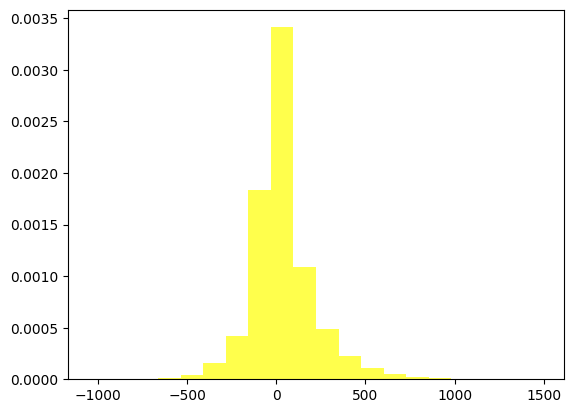

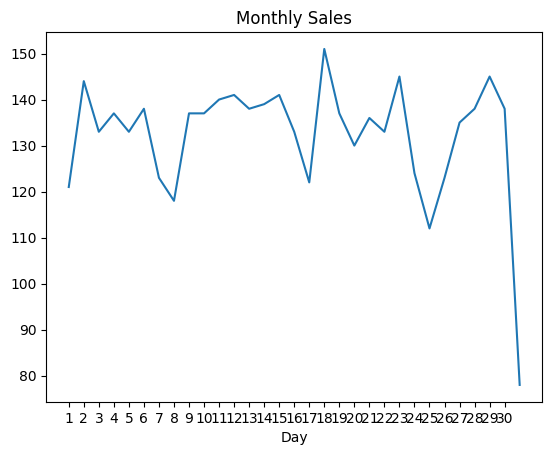

In [8]:
plt.hist(df['Amount'], 20, density=1, facecolor="yellow", alpha=0.7)
plt.show()

test = df['Amount'].groupby(df['Day']).size()
plot_month = test.plot(title = 'Monthly Sales' , xticks= (range(1, 31)))


In [11]:
positive = df.Amount[df['Amount'] > 0].count()
negative = df.Amount[df['Amount'] < 0].count()
print( 'positive = ', positive, 'negative = ', negative)

positive =  1968 negative =  2131


As you can see, there are more negative than positive values for amounts. At this point one would investigate why the company is recording negative values. Transactions made on credit, among other causes, may inform the analysis

In [12]:
sales_by_card = df.groupby('Transaction_Type').size()

print(sales_by_card)

Transaction_Type
Card    2811
Cash    1289
dtype: int64


The code abobe display sales by card

Sales by Month

Text(0, 0.5, 'Total Sales')

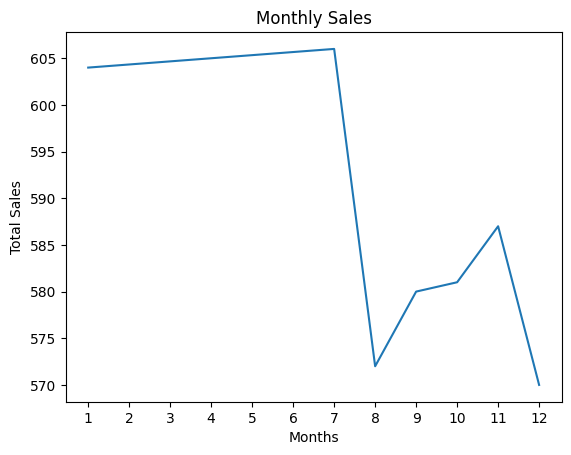

In [13]:
sales_by_month = df.groupby('Month').size()
plot_month = sales_by_month.plot(title = 'Monthly Sales' , xticks= (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12))
plot_month.set_xlabel('Months')
plot_month.set_ylabel('Total Sales')

This shows that from January to July the sales were almost steady but then something happened and the sales declined rapidly. This can show that an investigation needs to be done on what changed around that time. This is how we explore our data and do investigations. Some assumptions would be that we changed the store's opening hours or that the vendors and suppliers had changed

Sales by Day

Text(0, 0.5, 'Total Sales')

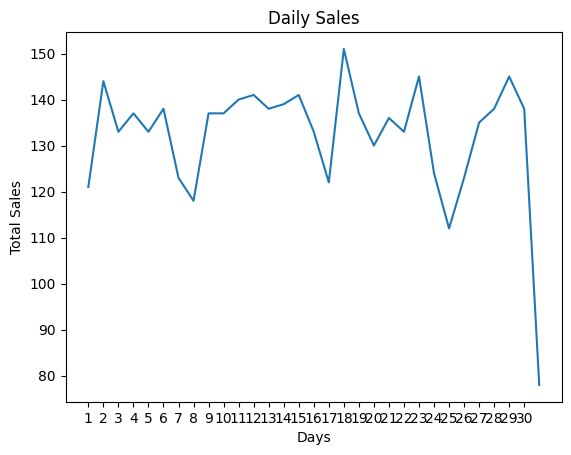

In [14]:
sales_by_month = df.groupby('Day').size()
plot_month = sales_by_month.plot(title = 'Daily Sales' , xticks= (range(1, 31)))
plot_month.set_xlabel('Days')
plot_month.set_ylabel('Total Sales')

Sales were fluctuating throughout the month but surprisingly there seems to be a significant drop at the end of the month. This is another point to investigate. We could assume that the sales would increase at the end of the month but this seems to be contrary. Finding the reasons behind it can be interesting. Do you have any assumptions?

Sale by Hour

Text(0, 0.5, 'Total Sales')

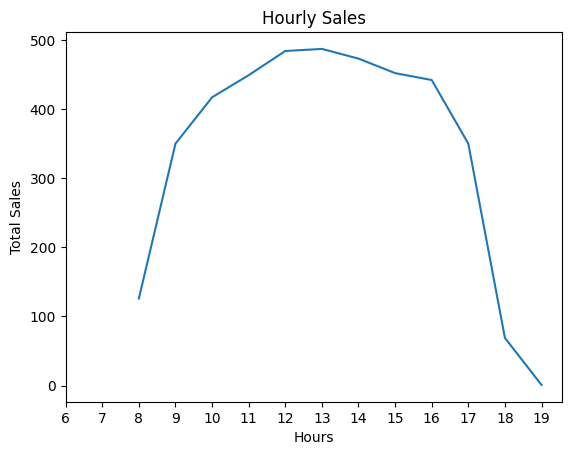

In [16]:
sales_by_month = df.groupby('Hour').size()
plot_month = sales_by_month.plot(title = 'Hourly Sales' , xticks=  (range(6, 20)))
plot_month.set_xlabel('Hours')
plot_month.set_ylabel('Total Sales') 

The sales seem to take a bell shape. The sales are highest from 11:00 AM to 16PM. More customers are visiting in the afternoon rather than at the opening and closing times. This is useful information for the administration department when it comes to managing staffing hours

Balance sheet example

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats


In [38]:
balance = pd.read_csv('balance.txt', sep=' ')
balance.head(10)

,Balance,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity
0,12.240798,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian
1,23.283334,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian
2,22.530409,104.593,7075,514,4,71,11,Male,No,No,Asian
3,27.652811,148.924,9504,681,3,36,11,Female,No,No,Asian
4,16.893978,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian
5,22.486178,80.180,8047,569,4,77,10,Male,No,No,Caucasian
6,10.574516,20.996,3388,259,2,37,12,Female,No,No,African American
7,14.576204,71.408,7114,512,2,87,9,Male,No,No,Asian
8,7.938090,15.125,3300,266,5,66,13,Female,No,No,Caucasian
9,17.756965,71.061,6819,491,3,41,19,Female,Yes,Yes,African American


What is missing from the data and how do you deal with it. What missing values are there? Where are the holes in our data? These are rows which are missing a value or have NaN instead of something like the rest of the column

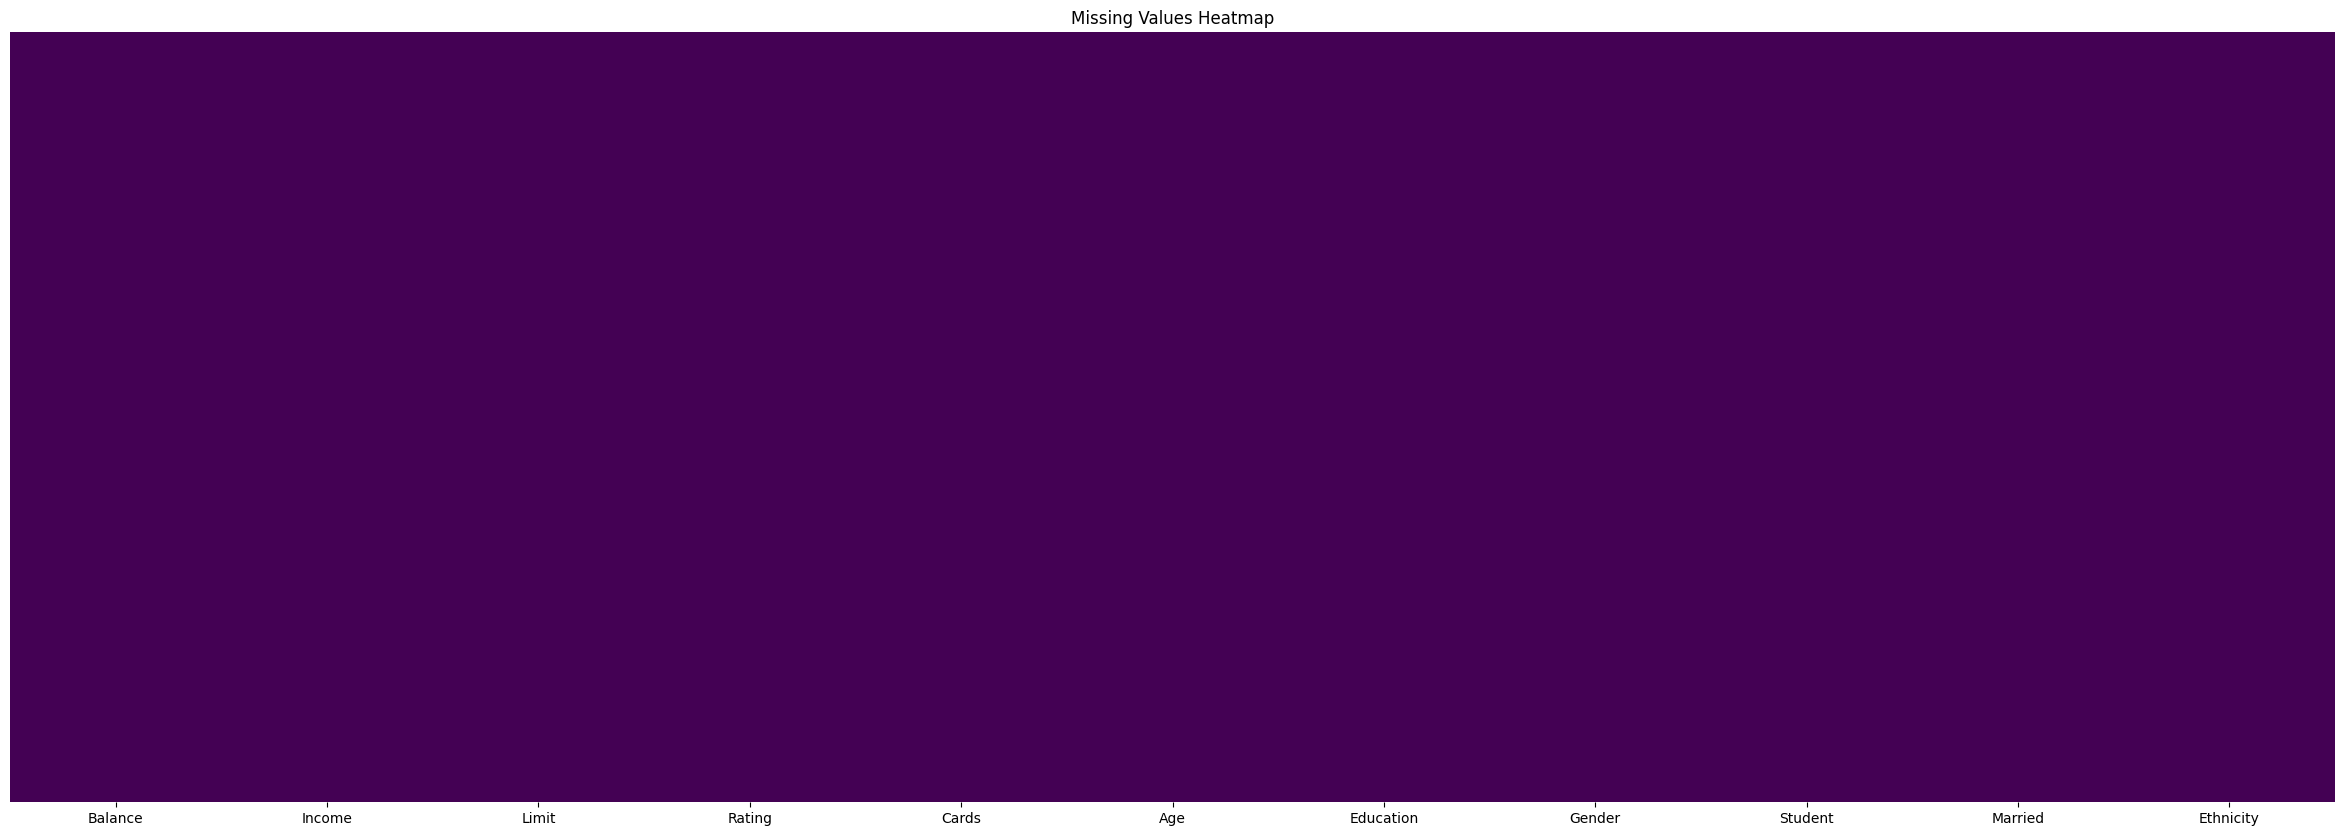

In [39]:
# Visualise missing values using seaborn heatmap
plt.figure(figsize=(30, 10)) # Set the figure size
sns.heatmap(balance.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()


We can now visualise the missing data and start strategising. We handled missing data in this dataset in the previous task to refresh go to previous tasks.

4. Where are the outliers and why should you pay attention to them. To perform our data analysis, let's create two new dataframes. We create onr for exploring discretised continous variables (continuous variables which have been sorted into some kind category) and another for exploring continuoes variables

In [30]:
df_bin = balance
df_con = balance

Lets explore each of these features inidividually

We go through each column iteratively and see which ones to use in our first models. Some may need more processing than others to get ready

In [40]:
# How many clients are Male and Female
fig = plt.figure(figsize=(20,1))
sns.countplot(y='Gender', data=df_bin);
print(df_bin.Gender.value_counts())

ValueError: Could not interpret value `Gender` for `y`. An entry with this name does not appear in `data`.

<Figure size 2000x100 with 0 Axes>

We can see that we have a few more females than males. This could be a coincidence or could be a real representation of the banks client list. Though the difference is not that significant

In [33]:
fig = plt.figure(figsize=(20, 10))
sns.countplot(y=df_bin['Cards'], data=df_bin);

KeyError: 'Cards'

<Figure size 2000x1000 with 0 Axes>

We can see with this feature, the values are numerical (1, 2 up to 8) but they are categories

We can deduce that most clients have 2 to 3 cards. An important thing to note is the average balance or income for every category

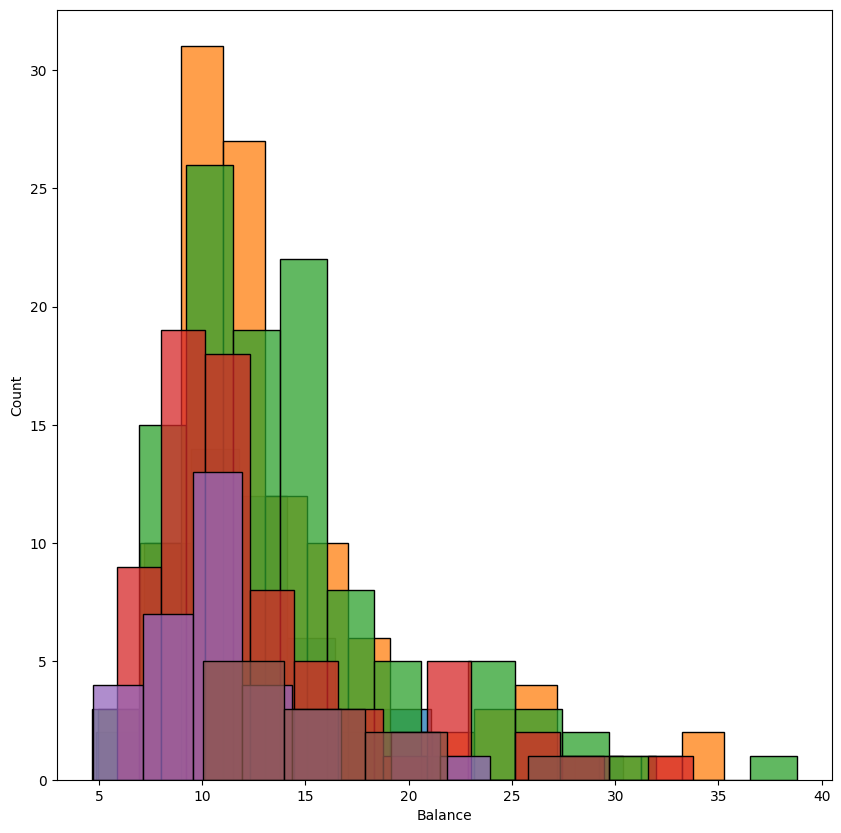

In [27]:
fig = plt.figure(figsize=(10, 10))
sns.histplot(df_bin.loc[df_bin['Cards'] == 1]['Balance'], kde_kws={'label': 'Cards = 1'});
sns.histplot(df_bin.loc[df_bin['Cards'] == 2]['Balance'], kde_kws={'label': 'Cards = 2'});
sns.histplot(df_bin.loc[df_bin['Cards'] == 3]['Balance'], kde_kws={'label': 'Cards = 2'});
sns.histplot(df_bin.loc[df_bin['Cards'] == 4]['Balance'], kde_kws={'label': 'Cards = 2'});
sns.histplot(df_bin.loc[df_bin['Cards'] == 5]['Balance'], kde_kws={'label': 'Cards = 2'});
sns.histplot(df_bin.loc[df_bin['Cards'] == 6]['Balance'], kde_kws={'label': 'Cards = 2'});


The plot above allows us to see that having different number of cards can be able to describe to us the balance that a client may have

5. How can you add, change or remove features to get more out of your data

Now let us look at the age variable, We might sat that it is a category variable but it has too many categories. Let us plot this to prove it

<Axes: xlabel='count', ylabel='Age'>

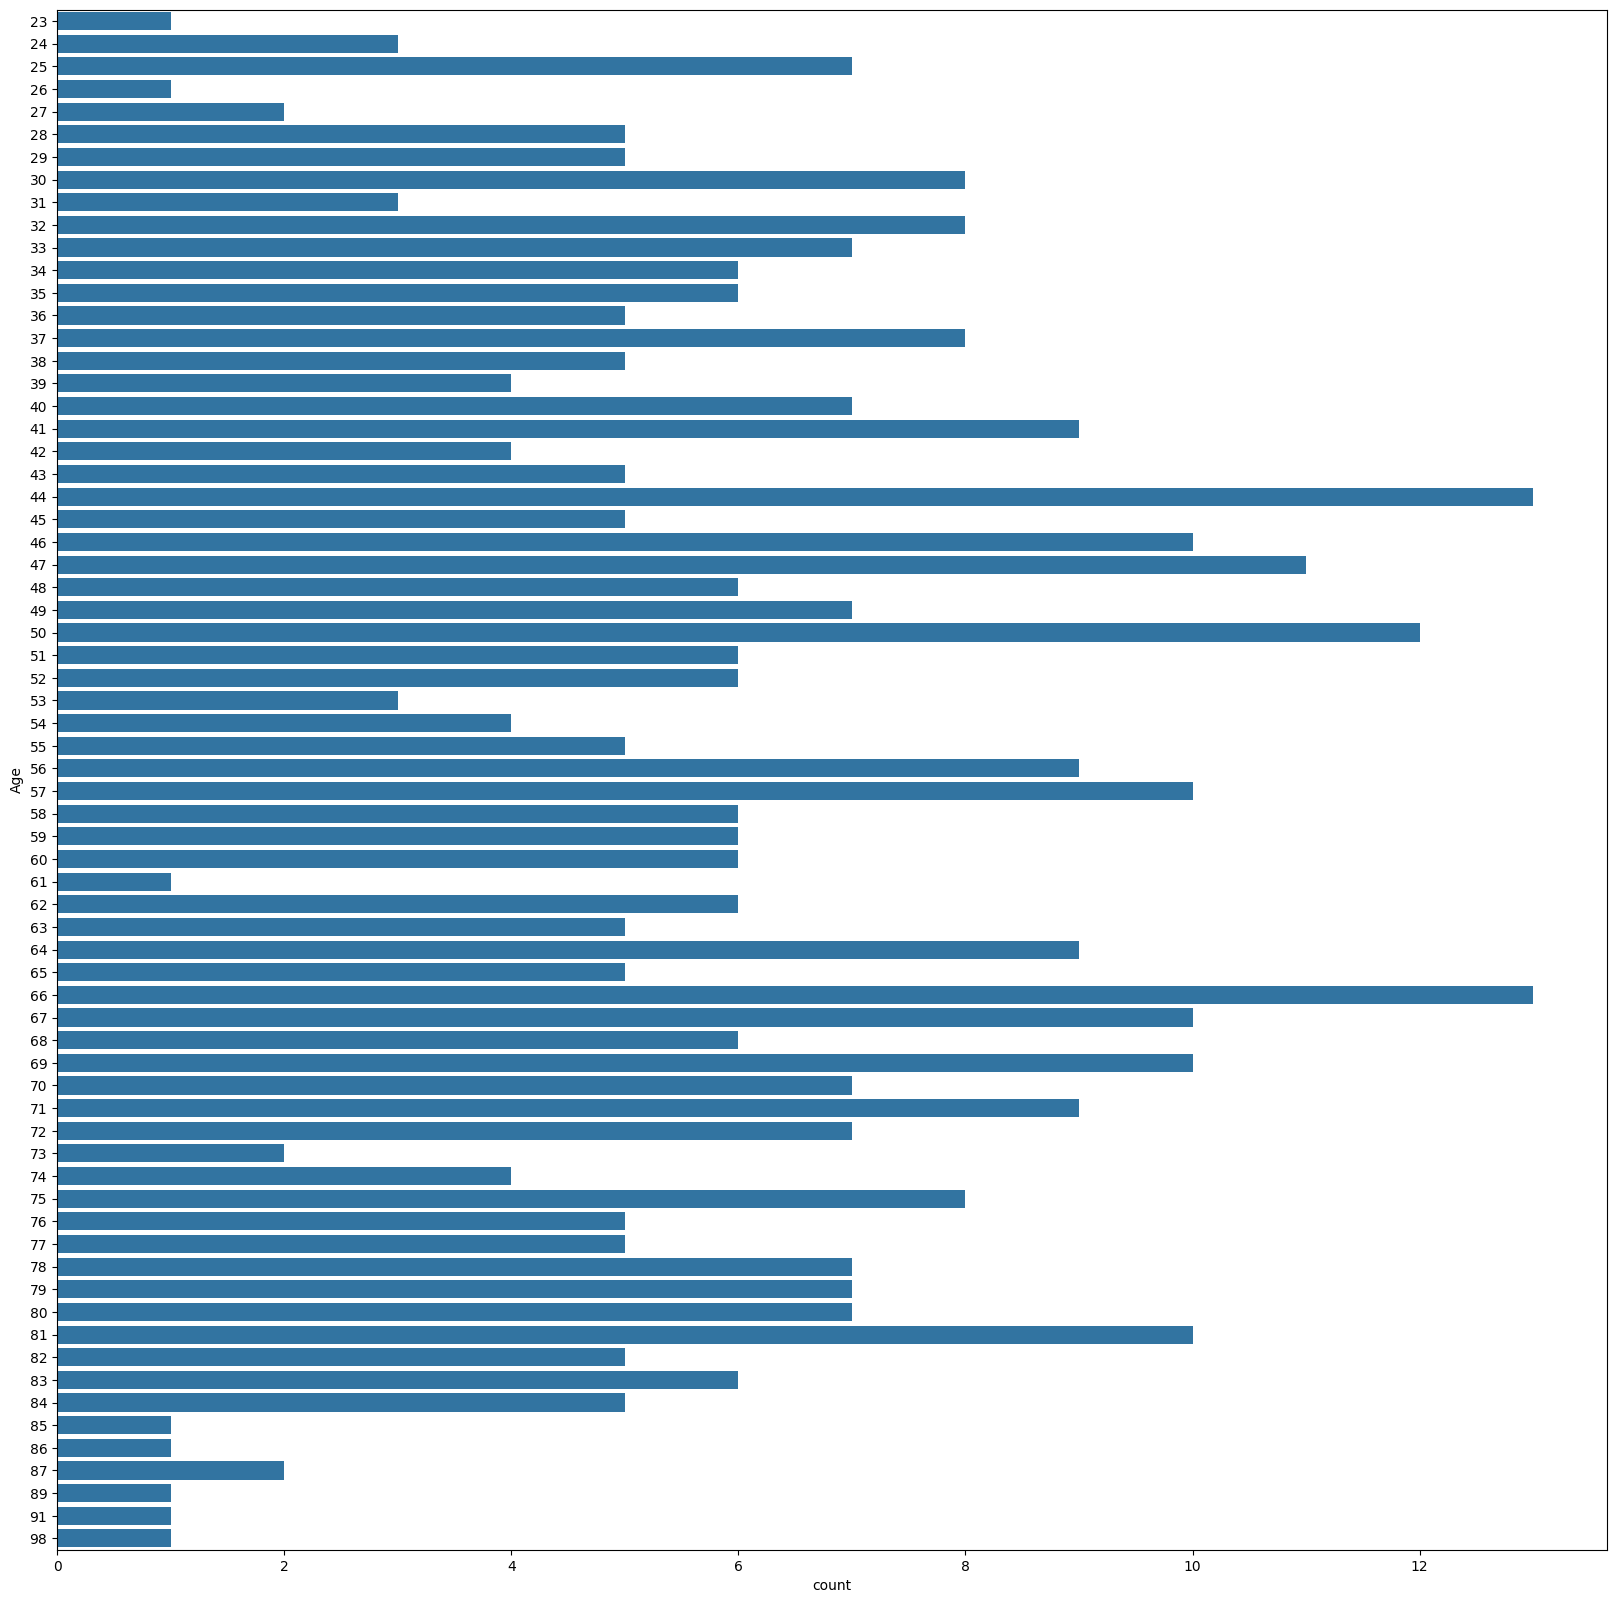

In [28]:
fig = plt.figure(figsize=(20, 20))
sns.countplot(y=df_bin['Age'], data=df_bin)

These are so many categories to analyse. Some categorical variables such as this can be put into groups. Since we are dealing with age, let us try and put the clients into age groups. We can do this by putting them into age groups of 10 or 5 years. For this analysis let us do so for 10 years. So we will start with age group 20-29 then 30-39 and so on.

In [35]:
df_bin['Age_group'] = pd.cut(df_bin['Age'], [20,29,39,49,59,69,79,89,99],
                    labels=['20-29','30-39','40-49','50-59','60-69','70-79'
                                     '80-89','90-99'])
fig = plt.figure(figsize=(20,10))
sns.countplot(y=df_bin['Age_group'], data=df_bin);

ValueError: Bin labels must be one fewer than the number of bin edges